# Chapitre 5 - Cours 3 : splines multidimensionnelles, noyaux (RKHS) et ondelettes

Ce dernier notebook de cours couvre la fin du chapitre 5 :

1. splines en dimension $p > 1$ : produits tensoriels et splines de plaque mince (§5.7) ;
2. régularisation et **espaces de Hilbert à noyau reproduisant** (RKHS), présentés pas à
   pas (§5.8, figures 5.13 à 5.15) ;
3. lissage par **ondelettes** de Haar : bases multirésolution, transformée rapide,
   seuillage doux (§5.9, figures 5.16 à 5.19).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch05_splines import (bspline_basis, SmoothingSpline, haar_transform,
                              inverse_haar_transform, haar_matrix, soft_threshold)
set_style()

## 1. Splines multidimensionnelles (§5.7)

**Produit tensoriel.** Si $\{h_{1j}(X_1)\}_{j \le M_1}$ et $\{h_{2k}(X_2)\}_{k \le M_2}$
sont des bases de fonctions d'une variable, les produits (éq. (5.35))

$$
g_{jk}(X) = h_{1j}(X_1)\,h_{2k}(X_2),\qquad j = 1..M_1,\ k = 1..M_2,
$$

forment une base de dimension $M_1 M_2$ pour des fonctions de $X = (X_1, X_2)$ :
$g(X) = \sum_{j,k}\theta_{jk}\,g_{jk}(X)$ (éq. (5.36)). La dimension croît
exponentiellement avec $p$ : c'est une manifestation du *fléau de la dimension*.

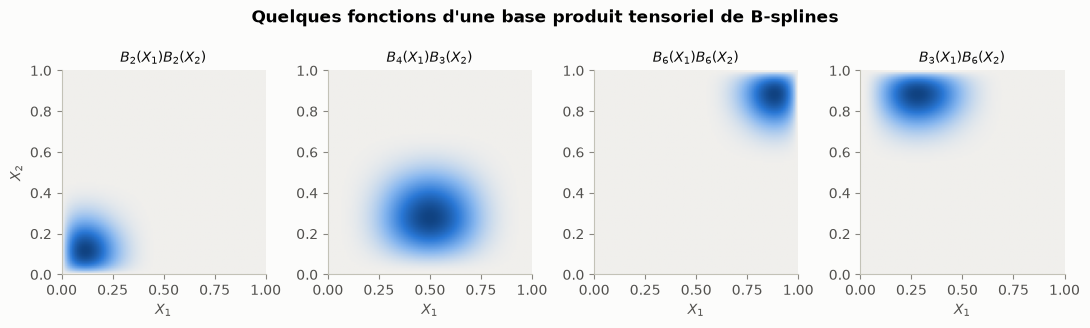

In [2]:
kn = np.linspace(0, 1, 5)[1:-1]
u = np.linspace(0, 1, 120)
B1 = bspline_basis(u, kn, 0, 1)            # 7 B-splines cubiques par axe
paires = [(1, 1), (3, 2), (5, 5), (2, 5)]
fig, axes = plt.subplots(1, 4, figsize=(11, 3.2))
for ax, (j, k) in zip(axes, paires):
    G = np.outer(B1[:, k], B1[:, j])
    ax.imshow(G, origin="lower", extent=[0, 1, 0, 1], cmap=SEQ)
    ax.set_title("$B_{%d}(X_1)B_{%d}(X_2)$" % (j + 1, k + 1), fontsize=10)
    ax.set_xlabel("$X_1$")
    ax.grid(False)
axes[0].set_ylabel("$X_2$")
fig.suptitle("Quelques fonctions d'une base produit tensoriel de B-splines", fontweight="bold")
plt.tight_layout()
plt.show()

**Splines de plaque mince.** La pénalité $\int f''^2$ se généralise en dimension 2 par
(éq. (5.38))

$$
J[f] = \iint_{\mathbb R^2}\left[\Big(\frac{\partial^2 f}{\partial x_1^2}\Big)^2
 + 2\Big(\frac{\partial^2 f}{\partial x_1\partial x_2}\Big)^2
 + \Big(\frac{\partial^2 f}{\partial x_2^2}\Big)^2\right]dx_1\,dx_2 .
$$

Le minimiseur de $\sum_i\{y_i - f(x_i)\}^2 + \lambda J[f]$ est une **spline de plaque
mince** (éq. (5.39)) :
$f(x) = \beta_0 + \beta^T x + \sum_{j=1}^{N}\alpha_j h_j(x)$ avec
$h_j(x) = \|x - x_j\|^2\log\|x - x_j\|$ (fonctions radiales). Les $\alpha_j$ doivent
vérifier des contraintes linéaires pour que $J[f]$ soit fini (exercice 5.14).

> **Remarque.** Une alternative plus économique est le modèle **additif**
> $f(X) = \alpha + \sum_j f_j(X_j)$ (chapitre 9), avec une pénalité
> $\sum_j\int f_j''^2$ (éq. (5.40)), ou des décompositions ANOVA avec quelques
> interactions (éq. (5.41)).

## 2. Régularisation et noyaux reproduisants (§5.8)

Le cadre général est (éq. (5.42))

$$
\min_{f \in \mathcal H}\ \sum_{i=1}^{N} L(y_i, f(x_i)) + \lambda J(f),
$$

où $L$ est une fonction de perte et $J$ une pénalité. La spline de lissage en est un cas
particulier ($L$ quadratique, $J(f) = \int f''^2$). Nous allons voir une famille de
pénalités pour laquelle ce problème de dimension infinie se ramène, comme pour les
splines, à un problème de dimension $N$.

### Noyaux : définition

Un **noyau** est une fonction $K : \mathbb R^p \times \mathbb R^p \to \mathbb R$
**symétrique** ($K(x, y) = K(y, x)$) et **(semi-)définie positive** : pour tous points
$x_1, \dots, x_n$, la **matrice de Gram** $\mathbf K = (K(x_i, x_j))_{i,j}$ est
semi-définie positive, i.e. $\alpha^T\mathbf K\alpha \ge 0$ pour tout $\alpha$.

Exemples :

- noyau polynomial $K(x, y) = (\langle x, y\rangle + 1)^d$ ;
- noyau gaussien (radial) $K(x, y) = e^{-\nu\|x - y\|^2}$.

> **Intuition.** $K(x, y)$ mesure une **similarité** entre $x$ et $y$. Penser à un
> produit scalaire $\langle h(x), h(y)\rangle$ entre des « caractéristiques » $h(x)$,
> éventuellement en nombre infini.

In [ ]:
rng = np.random.RandomState(0)
pts = rng.randn(30, 2)
gauss = lambda A, B, nu=1.0: np.exp(-nu * ((A[:, None, :] - B[None, :, :]) ** 2).sum(-1))
poly = lambda A, B, d=2: (A @ B.T + 1) ** d
for nom, Kf in [("gaussien", gauss), ("polynomial d=2", poly)]:
    Kg = Kf(pts, pts)
    print("noyau %-15s : symétrique %s, plus petite valeur propre = %.2e"
          % (nom, np.allclose(Kg, Kg.T), np.linalg.eigvalsh(Kg).min()))